# Review 2: Text Mining of Movie Overviews (TMDB)

**Issues:** 18-19 (Review 2)

Core analyses (kept deliberately focused):
1. Preprocessing
2. Words linked to high vs low ratings (with significance tests)
3. Word clouds and bigrams
4. Topic modelling (LDA), with topic number chosen by coherence
5. Topics vs rating, genre and year
6. Sentiment of overviews vs rating
7. Export of results for the dashboard (`data/text/*.csv`)

Data: `data/processed/tmdb_clean.csv`. Only movies with 20 or more votes are used, so ratings are reliable.

## 1. Setup and settings

In [6]:
# %pip install wordcloud textblob
import os, ast, re, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import chi2 as chi2d, chi2_contingency, spearmanr, mannwhitneyu, kruskal
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation
from wordcloud import WordCloud
from textblob import TextBlob

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

ROOT = ".."                      # notebook is in notebooks/; use "." if you run from the repo root
IN = "data/processed/tmdb_clean.csv"
OUT = f"{ROOT}/data/text"        # CSV files for the dashboard
FIG = f"{ROOT}/reports/figures/text"
MIN_V, HIGH, SEED = 20, 6.5, 42
K_RANGE = [4, 6, 8, 10, 12]      # topic numbers to try
FORCE_K = None                   # set e.g. 8 to override the automatic choice
os.makedirs(OUT, exist_ok=True); os.makedirs(FIG, exist_ok=True)

def save(name):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. Load and preprocess

In [7]:
df = pd.read_csv(IN, parse_dates=["release_date"])
df["genres"] = df["genres"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
m = df[df["vote_count"] >= MIN_V].copy().reset_index(drop=True)
m["high_rated"] = (m["vote_average"] >= HIGH).astype(int)
print(f"clean movies: {len(df):,} | used (>= {MIN_V} votes): {len(m):,} | high-rated: {m['high_rated'].mean():.1%}")

# generic words and text fragments (e.g. '19th century' -> 'th century', 'Pokemon' -> 'pok mon')
EXTRA = {"film", "movie", "story", "life", "finds", "new", "one", "two", "must", "world", "man", "young",
         "woman", "find", "group", "takes", "set", "help", "time", "day", "back", "old", "gets", "makes",
         "just", "year", "years", "like", "way", "begins", "comes", "turns", "soon", "people", "different",
         "leads", "face", "th", "nd", "rd", "st", "pok", "mon"}
STOP = sorted(set(ENGLISH_STOP_WORDS) | EXTRA)

def clean(t):
    t = re.sub(r"[^a-z\s]", " ", str(t).lower())     # lowercase, keep letters only
    return re.sub(r"\s+", " ", t).strip()

m["clean"] = m["overview"].apply(clean)
m["words"] = m["clean"].str.split().str.len()
print("average words per overview:", round(m["words"].mean(), 1), "| stop words:", len(STOP))
print("sample:", m["clean"].iloc[0][:150])

clean movies: 15,386 | used (>= 20 votes): 10,078 | high-rated: 39.0%
average words per overview: 49.6 | stop words: 356
sample: the story of the legendary steel driving folk hero born with a hammer in his hands who pitted his strength against a mighty railroad building machine


## 3. Words linked to high vs low ratings

The two groups have different sizes, so we compare the **share of movies containing a word** (not raw counts).
A chi-square test with Bonferroni correction checks which words are significantly linked to a rating group.
Effect size is the phi coefficient.

terms tested: 2000 | Bonferroni alpha: 2.5e-05 | significant: 19


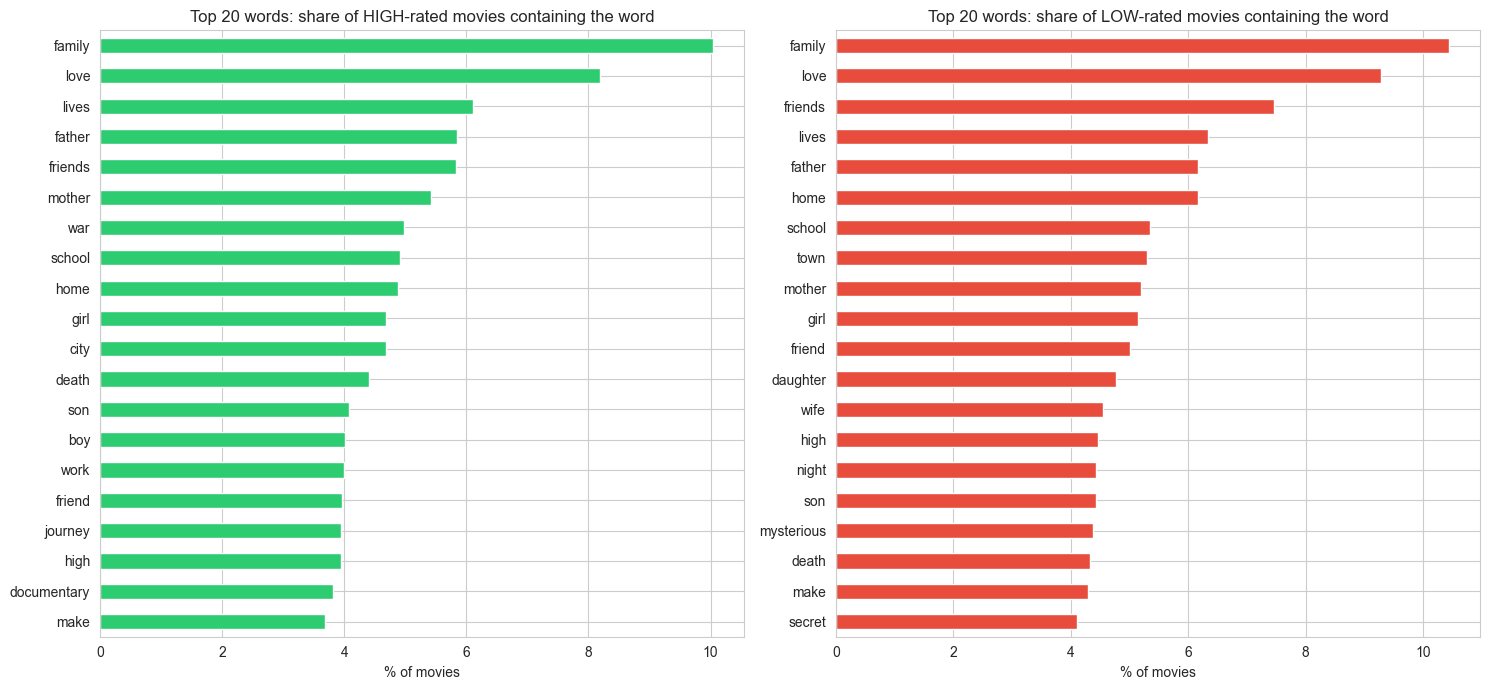

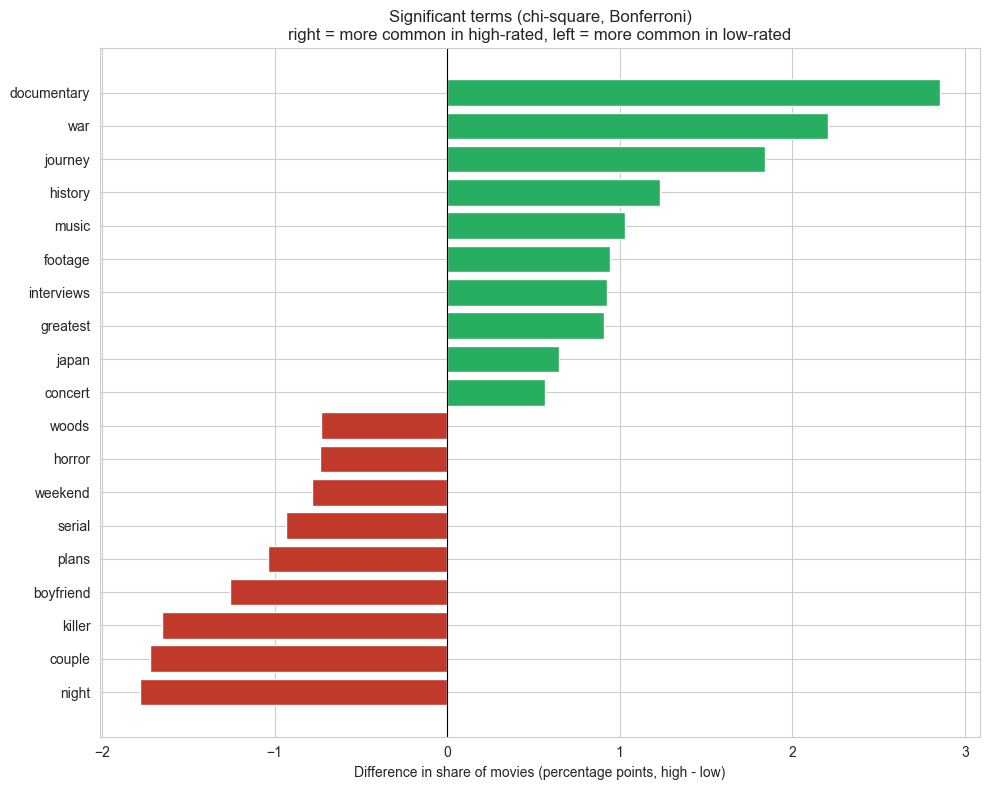

       term  share_high  share_low    phi  p_value
documentary      0.0382     0.0096 0.0978      0.0
        war      0.0499     0.0278 0.0574      0.0
    journey      0.0394     0.0210 0.0544      0.0
    history      0.0252     0.0129 0.0457      0.0
      music      0.0191     0.0088 0.0447      0.0
    footage      0.0127     0.0033 0.0556      0.0
 interviews      0.0117     0.0024 0.0582      0.0
   greatest      0.0148     0.0057 0.0462      0.0
      japan      0.0089     0.0024 0.0449      0.0
    concert      0.0076     0.0020 0.0430      0.0
      woods      0.0023     0.0096 0.0435      0.0
     horror      0.0025     0.0099 0.0430      0.0
    weekend      0.0018     0.0096 0.0473      0.0
     serial      0.0043     0.0137 0.0457      0.0
      plans      0.0081     0.0185 0.0425      0.0
  boyfriend      0.0079     0.0205 0.0497      0.0
     killer      0.0137     0.0303 0.0529      0.0
     couple      0.0181     0.0353 0.0505      0.0
      night      0.0265     0.0

In [8]:
cv = CountVectorizer(stop_words=STOP, binary=True, min_df=5, max_features=2000, token_pattern=r"(?u)\b[a-z]{3,}\b")
X = cv.fit_transform(m["clean"]); terms = np.array(cv.get_feature_names_out())
hi = m["high_rated"].values == 1
n, nh, nl = len(m), hi.sum(), (~hi).sum()

a = np.asarray(X[hi].sum(axis=0)).ravel(); b = nh - a          # high-rated: with / without the word
c = np.asarray(X[~hi].sum(axis=0)).ravel(); d = nl - c         # low-rated: with / without the word
den = (a + b) * (c + d) * (a + c) * (b + d)
chi = np.where(den > 0, n * (a * d - b * c) ** 2 / np.where(den > 0, den, 1), 0)
tw = pd.DataFrame({"term": terms, "share_high": a / nh, "share_low": c / nl, "chi2": chi,
                   "p_value": chi2d.sf(chi, 1), "phi": np.sqrt(chi / n)})
tw["diff"] = tw["share_high"] - tw["share_low"]
alpha = 0.05 / len(tw)
tw["significant"] = tw["p_value"] < alpha
tw["direction"] = np.where(tw["diff"] > 0, "high-rated", "low-rated")
print(f"terms tested: {len(tw)} | Bonferroni alpha: {alpha:.1e} | significant: {tw['significant'].sum()}")

fig, ax = plt.subplots(1, 2, figsize=(15, 7))
(tw.nlargest(20, "share_high").set_index("term")["share_high"] * 100).sort_values().plot(kind="barh", ax=ax[0], color="#2ecc71")
ax[0].set_title("Top 20 words: share of HIGH-rated movies containing the word"); ax[0].set_xlabel("% of movies")
(tw.nlargest(20, "share_low").set_index("term")["share_low"] * 100).sort_values().plot(kind="barh", ax=ax[1], color="#e74c3c")
ax[1].set_title("Top 20 words: share of LOW-rated movies containing the word"); ax[1].set_xlabel("% of movies")
ax[0].set_ylabel(""); ax[1].set_ylabel(""); save("word_share_high_vs_low")

sg = tw[tw["significant"]]
pick = pd.concat([sg.nlargest(12, "diff"), sg.nsmallest(12, "diff")]).drop_duplicates("term").sort_values("diff")
plt.figure(figsize=(10, 8))
plt.barh(pick["term"], pick["diff"] * 100, color=["#27ae60" if v > 0 else "#c0392b" for v in pick["diff"]])
plt.axvline(0, color="k", lw=0.8)
plt.title("Significant terms (chi-square, Bonferroni)\nright = more common in high-rated, left = more common in low-rated")
plt.xlabel("Difference in share of movies (percentage points, high - low)"); save("significant_terms")
print(pick.sort_values("diff", ascending=False)[["term", "share_high", "share_low", "phi", "p_value"]].round(4).to_string(index=False))

## 4. Word clouds and bigrams

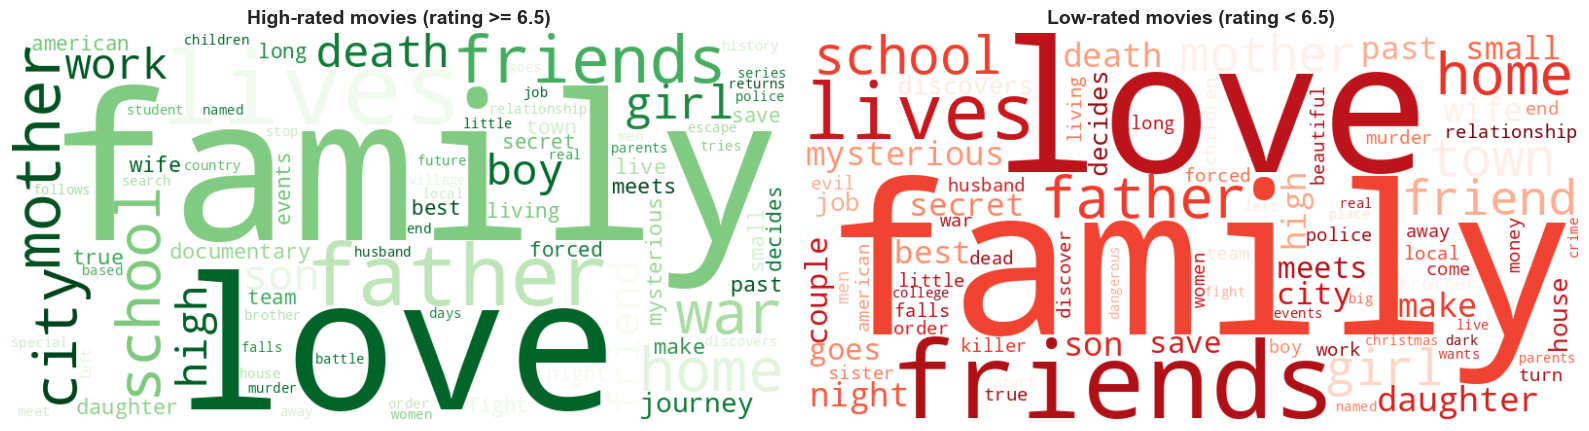

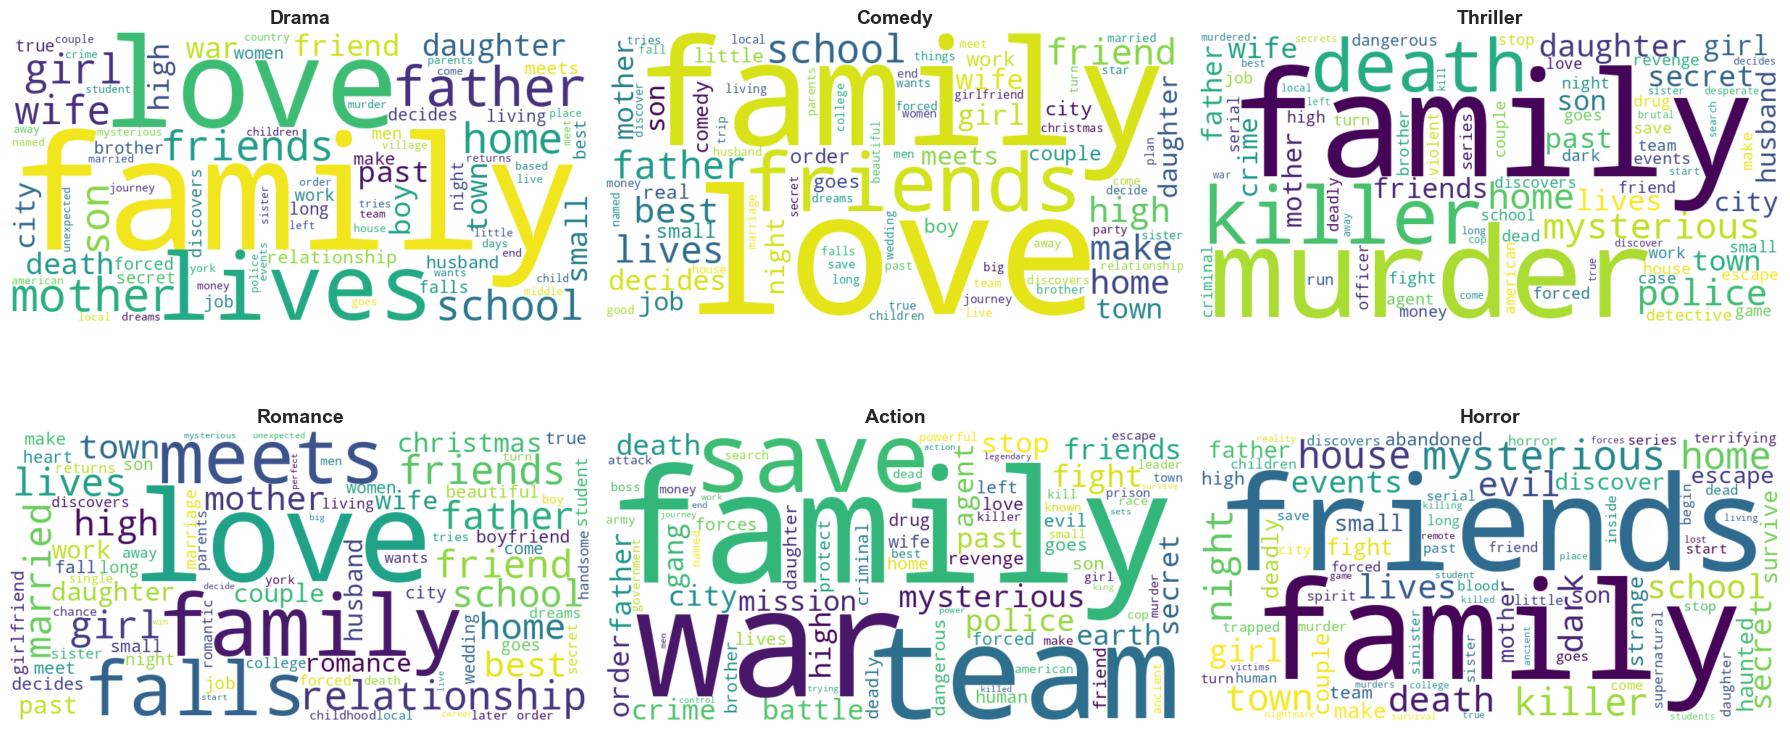

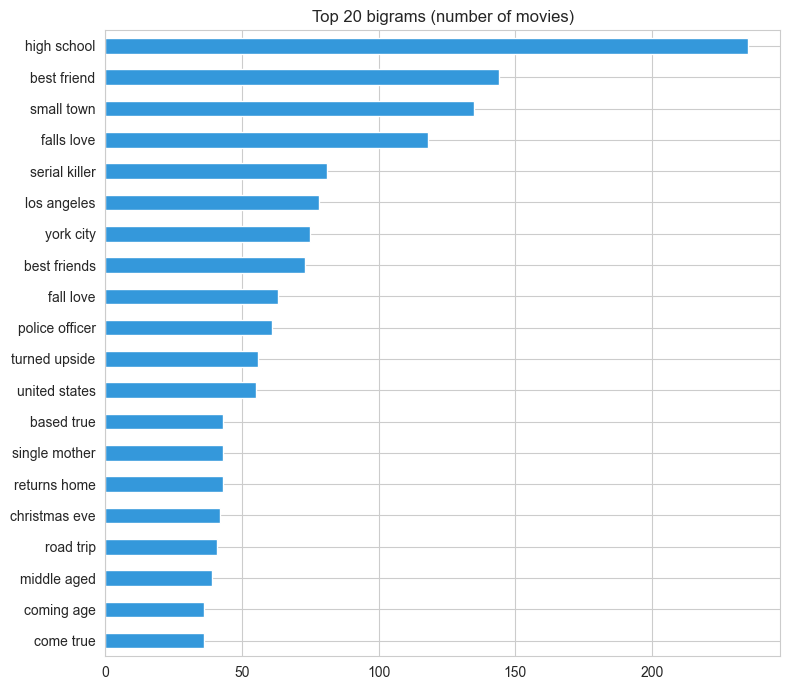

        bigram  movies  share_high  share_low
   high school     235    0.020860   0.024890
   best friend     144    0.009921   0.017082
    small town     135    0.008649   0.016431
    falls love     118    0.010430   0.012526
 serial killer      81    0.003561   0.010900
   los angeles      78    0.006614   0.008459
     york city      75    0.009158   0.006345
  best friends      73    0.006614   0.007646
     fall love      63    0.005851   0.006507
police officer      61    0.006105   0.006019
 turned upside      56    0.004579   0.006182
 united states      55    0.006105   0.005043
    based true      43    0.005597   0.003416
  returns home      43    0.003561   0.004718
 single mother      43    0.005342   0.003579


In [9]:
def cloud(ax, freq, cmap, title):
    ax.imshow(WordCloud(width=800, height=400, background_color="white", colormap=cmap, max_words=80)
              .generate_from_frequencies(freq), interpolation="bilinear")
    ax.set_title(title, fontsize=14, fontweight="bold"); ax.axis("off")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
cloud(ax[0], dict(zip(terms, tw["share_high"] + 1e-9)), "Greens", "High-rated movies (rating >= %.1f)" % HIGH)
cloud(ax[1], dict(zip(terms, tw["share_low"] + 1e-9)), "Reds", "Low-rated movies (rating < %.1f)" % HIGH)
save("wordclouds_rating")

top_g = m.explode("genres")["genres"].value_counts().head(6).index.tolist()
gw, rows = {}, []
for g in top_g:
    mk = m["genres"].apply(lambda l: g in l).values
    sh = np.asarray(X[mk].sum(axis=0)).ravel() / mk.sum()
    gw[g] = dict(zip(terms, sh + 1e-9))
    rows += [{"genre": g, "term": t, "share": s} for t, s in pd.Series(sh, index=terms).nlargest(30).items()]
genre_words = pd.DataFrame(rows)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, g in zip(axes.ravel(), top_g): cloud(ax, gw[g], "viridis", g)
save("wordclouds_genre")

bv = CountVectorizer(ngram_range=(2, 2), stop_words=STOP, binary=True, min_df=5, max_features=500,
                     token_pattern=r"(?u)\b[a-z]{3,}\b")
BX = bv.fit_transform(m["clean"]); bt = np.array(bv.get_feature_names_out())
bg = pd.DataFrame({"bigram": bt, "movies": np.asarray(BX.sum(axis=0)).ravel(),
                   "share_high": np.asarray(BX[hi].sum(axis=0)).ravel() / nh,
                   "share_low": np.asarray(BX[~hi].sum(axis=0)).ravel() / nl}).sort_values("movies", ascending=False)
bg.head(20).set_index("bigram")["movies"].sort_values().plot(kind="barh", figsize=(8, 7), color="#3498db")
plt.title("Top 20 bigrams (number of movies)"); plt.ylabel(""); save("top_bigrams")
print(bg.head(15).to_string(index=False))

## 5. Topic modelling (LDA)

The number of topics is chosen by **NPMI coherence** (higher = topics whose top words really appear together).

 topics  mean_coherence  weakest_topic
      4          0.0338         0.0077
      6          0.0278        -0.0377
      8          0.0228        -0.0459
     10          0.0323        -0.0621
     12          0.0214        -0.0346
topics used: 4


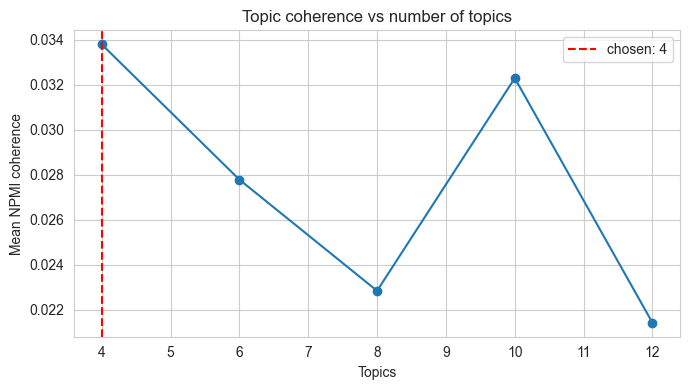

Topic 1 (coherence 0.008): school, high, war, team, children, fight, parents, journey, american, human
Topic 2 (coherence 0.066): love, family, girl, father, mother, past, friends, friend, town, daughter
Topic 3 (coherence 0.029): night, women, make, game, lives, power, live, career, husband, company
Topic 4 (coherence 0.032): house, police, murder, death, killer, city, family, money, crime, secret


In [10]:
cvt = CountVectorizer(stop_words=STOP, max_features=2000, min_df=10, max_df=0.7, token_pattern=r"(?u)\b[a-z]{3,}\b")
dt = cvt.fit_transform(m["clean"]); fn = np.array(cvt.get_feature_names_out())
nd = dt.shape[0]
Bm = (dt > 0).astype(np.float32); co = (Bm.T @ Bm).toarray(); dfw = np.diag(co)    # co-occurrence counts

def npmi(comp, top=10):
    out, eps = [], 1e-12
    for t in comp:
        ix = t.argsort()[::-1][:top]; s = []
        for i in range(top):
            for j in range(i + 1, top):
                p12, p1, p2 = co[ix[i], ix[j]] / nd, dfw[ix[i]] / nd, dfw[ix[j]] / nd
                s.append(np.log((p12 + eps) / (p1 * p2)) / (-np.log(p12 + eps)))
        out.append(np.mean(s))
    return np.array(out)

models, scan = {}, []
for k in K_RANGE:
    l = LatentDirichletAllocation(n_components=k, random_state=SEED, max_iter=20, learning_method="online", n_jobs=-1).fit(dt)
    cs = npmi(l.components_); models[k] = l
    scan.append({"topics": k, "mean_coherence": cs.mean(), "weakest_topic": cs.min()})
scan = pd.DataFrame(scan); print(scan.round(4).to_string(index=False))
K = FORCE_K or int(scan.loc[scan["mean_coherence"].idxmax(), "topics"])
print("topics used:", K)
plt.figure(figsize=(7, 4)); plt.plot(scan["topics"], scan["mean_coherence"], marker="o")
plt.axvline(K, color="red", ls="--", label=f"chosen: {K}"); plt.legend()
plt.title("Topic coherence vs number of topics"); plt.xlabel("Topics"); plt.ylabel("Mean NPMI coherence"); save("topic_coherence_scan")

lda = models[K]; tp = lda.transform(dt); coh = npmi(lda.components_)
m["topic"] = tp.argmax(axis=1) + 1; m["topic_conf"] = tp.max(axis=1)

# give each topic a short name AFTER reading the top words, e.g. {1: "War and documentaries", 2: "Crime"}
TOPIC_NAMES = {}
top_words = {i + 1: [fn[j] for j in t.argsort()[::-1][:10]] for i, t in enumerate(lda.components_)}
name = {i: TOPIC_NAMES.get(i, f"T{i}: " + ", ".join(w[:3])) for i, w in top_words.items()}
m["topic_name"] = m["topic"].map(name)
for i, w in top_words.items(): print(f"Topic {i} (coherence {coh[i-1]:.3f}): {', '.join(w)}")

## 6. Topics vs rating, genre and year

                      topic_name  movies  avg_rating  high_rated_pct  avg_popularity  coherence
topic                                                                                          
1          T1: school, high, war    2015       6.160           0.438           3.862      0.008
2         T2: love, family, girl    2905       6.122           0.362           3.103      0.066
3         T3: night, women, make    1693       6.313           0.469           2.982      0.029
4      T4: house, police, murder    3465       6.007           0.347           3.603      0.032

Kruskal-Wallis (rating differs by topic): H = 115.1, p = 8.55e-25
Chi-square (high-rated share differs by topic): chi2 = 100.0, p = 1.56e-21


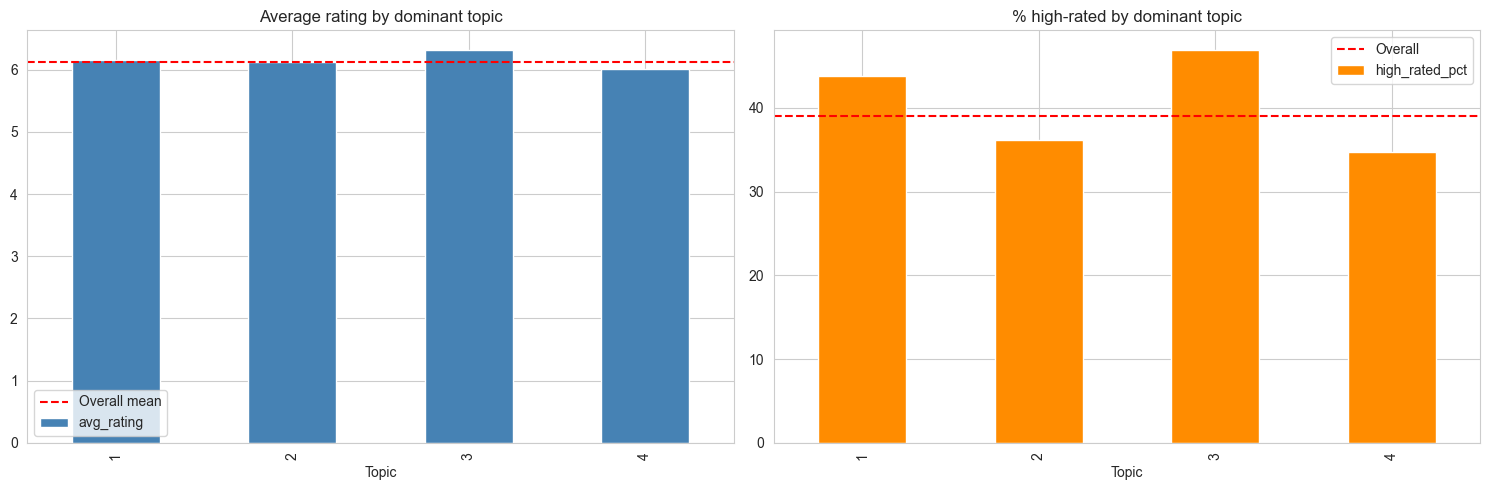

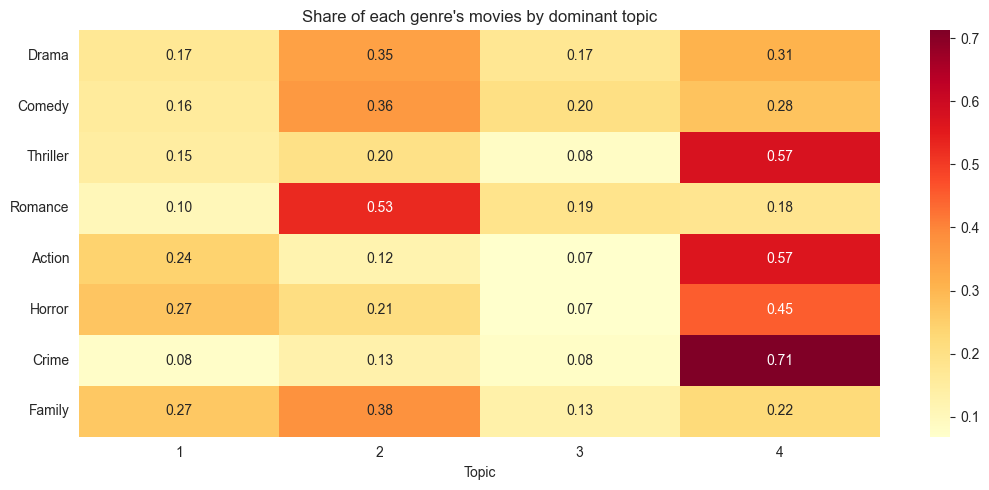

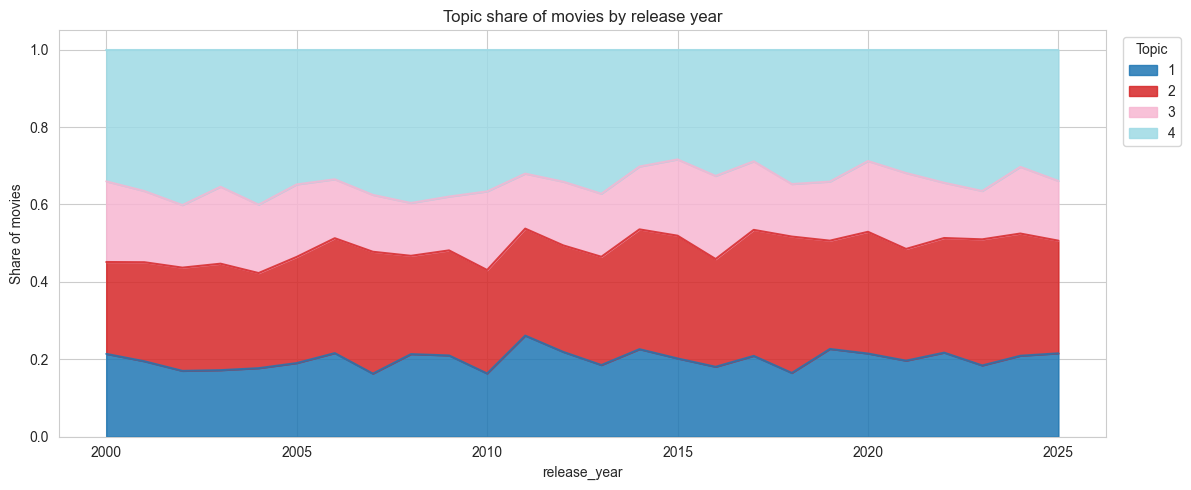

In [11]:
tr = m.groupby("topic").agg(movies=("id", "size"), avg_rating=("vote_average", "mean"),
                            high_rated_pct=("high_rated", "mean"), avg_popularity=("popularity", "mean")).round(3)
tr = tr.reindex(range(1, K + 1)); tr["movies"] = tr["movies"].fillna(0).astype(int)     # keeps topics that are nobody's main topic
tr["topic_name"] = tr.index.map(name); tr["coherence"] = coh.round(3); tr["top_words"] = [", ".join(top_words[i]) for i in tr.index]
print(tr[["topic_name", "movies", "avg_rating", "high_rated_pct", "avg_popularity", "coherence"]].to_string())

kw = kruskal(*[g["vote_average"].values for _, g in m.groupby("topic")])
ch = chi2_contingency(pd.crosstab(m["topic"], m["high_rated"]))
print(f"\nKruskal-Wallis (rating differs by topic): H = {kw.statistic:.1f}, p = {kw.pvalue:.2e}")
print(f"Chi-square (high-rated share differs by topic): chi2 = {ch[0]:.1f}, p = {ch[1]:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
tr["avg_rating"].plot(kind="bar", ax=ax[0], color="steelblue"); ax[0].axhline(m["vote_average"].mean(), color="red", ls="--", label="Overall mean")
ax[0].set_title("Average rating by dominant topic"); ax[0].set_xlabel("Topic"); ax[0].legend()
(tr["high_rated_pct"] * 100).plot(kind="bar", ax=ax[1], color="darkorange"); ax[1].axhline(m["high_rated"].mean() * 100, color="red", ls="--", label="Overall")
ax[1].set_title("% high-rated by dominant topic"); ax[1].set_xlabel("Topic"); ax[1].legend(); save("topic_vs_rating")

top8 = m.explode("genres")["genres"].value_counts().head(8).index.tolist()
tg = pd.DataFrame({g: m[m["genres"].apply(lambda l: g in l)]["topic"].value_counts(normalize=True) for g in top8}).T.fillna(0)
tg = tg.reindex(columns=range(1, K + 1), fill_value=0)
plt.figure(figsize=(11, 5)); sns.heatmap(tg, annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("Share of each genre's movies by dominant topic"); plt.xlabel("Topic"); plt.ylabel(""); save("topic_genre_heatmap")

ty = pd.crosstab(m["release_year"], m["topic"], normalize="index")
ty.plot.area(figsize=(12, 5), colormap="tab20", alpha=0.85); plt.legend(title="Topic", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("Topic share of movies by release year"); plt.ylabel("Share of movies"); save("topic_share_by_year")

## 7. Sentiment of overviews

TextBlob scores the tone of the plot summary (polarity -1 to +1, subjectivity 0 to 1). This is the tone of the *description*, not audience opinion.

Polarity vs rating (Spearman): r = 0.083, p = 5.5e-17
Subjectivity vs rating (Spearman): r = -0.035, p = 5.1e-04
Polarity high vs low (Mann-Whitney): p = 1.0e-09
            polarity  subjectivity
Low-rated     0.0364        0.4701
High-rated    0.0647        0.4581


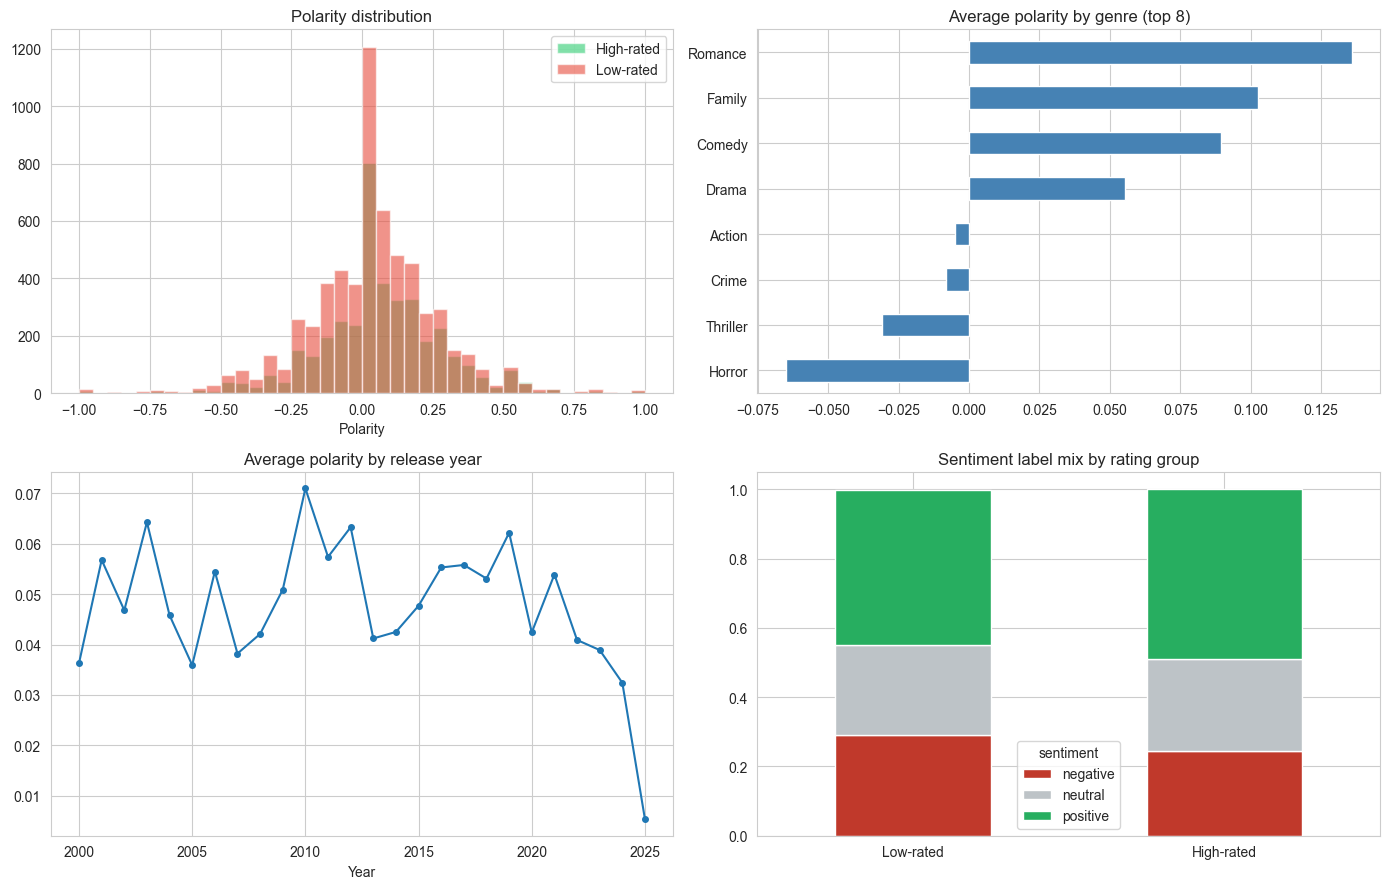

          polarity  subjectivity
Horror     -0.0651        0.4987
Thriller   -0.0309        0.4733
Crime      -0.0083        0.4610
Action     -0.0049        0.4696
Drama       0.0554        0.4553
Comedy      0.0894        0.4767
Family      0.1027        0.4917
Romance     0.1359        0.4788
sentiment   negative  neutral  positive
Low-rated      0.292    0.259     0.448
High-rated     0.245    0.265     0.490


In [12]:
sb = m["overview"].apply(lambda x: TextBlob(str(x)).sentiment)
m["polarity"] = [s.polarity for s in sb]; m["subjectivity"] = [s.subjectivity for s in sb]
m["sentiment"] = pd.cut(m["polarity"], [-1.01, -0.05, 0.05, 1.01], labels=["negative", "neutral", "positive"])

r1, p1 = spearmanr(m["polarity"], m["vote_average"]); r2, p2 = spearmanr(m["subjectivity"], m["vote_average"])
u = mannwhitneyu(m.loc[hi, "polarity"], m.loc[~hi, "polarity"])
print(f"Polarity vs rating (Spearman): r = {r1:.3f}, p = {p1:.1e}")
print(f"Subjectivity vs rating (Spearman): r = {r2:.3f}, p = {p2:.1e}")
print(f"Polarity high vs low (Mann-Whitney): p = {u.pvalue:.1e}")
sr = m.groupby("high_rated").agg(polarity=("polarity", "mean"), subjectivity=("subjectivity", "mean")).round(4)
sr.index = ["Low-rated", "High-rated"]; print(sr)

sgn = pd.DataFrame({g: m[m["genres"].apply(lambda l: g in l)][["polarity", "subjectivity"]].mean() for g in top8}).T.round(4)
sy = m.groupby("release_year").agg(polarity=("polarity", "mean"), subjectivity=("subjectivity", "mean"), movies=("id", "size")).round(4)
mix = pd.crosstab(m["high_rated"], m["sentiment"], normalize="index").round(3); mix.index = ["Low-rated", "High-rated"]

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for v, col, nm in [(1, "#2ecc71", "High-rated"), (0, "#e74c3c", "Low-rated")]:
    ax[0, 0].hist(m.loc[m["high_rated"] == v, "polarity"], bins=40, alpha=0.6, color=col, label=nm)
ax[0, 0].set_title("Polarity distribution"); ax[0, 0].set_xlabel("Polarity"); ax[0, 0].legend()
sgn["polarity"].sort_values().plot(kind="barh", ax=ax[0, 1], color="steelblue"); ax[0, 1].set_title("Average polarity by genre (top 8)")
ax[1, 0].plot(sy.index, sy["polarity"], marker="o", ms=4); ax[1, 0].set_title("Average polarity by release year"); ax[1, 0].set_xlabel("Year")
mix.plot(kind="bar", stacked=True, ax=ax[1, 1], color=["#c0392b", "#bdc3c7", "#27ae60"]); ax[1, 1].set_title("Sentiment label mix by rating group")
ax[1, 1].tick_params(axis="x", rotation=0); save("sentiment_analysis")
print(sgn.sort_values("polarity")); print(mix)

## 8. Summary of evaluation numbers

In [13]:
summ = pd.DataFrame([
    ("movies analysed", len(m)), ("high-rated share", round(m["high_rated"].mean(), 3)),
    ("terms tested", len(tw)), ("terms significant (Bonferroni)", int(tw["significant"].sum())),
    ("topics chosen", K), ("mean topic coherence (NPMI)", round(float(coh.mean()), 4)),
    ("Kruskal-Wallis p (rating by topic)", float(kw.pvalue)), ("chi-square p (high-rated by topic)", float(ch[1])),
    ("polarity vs rating Spearman r", round(r1, 4)), ("polarity vs rating p", float(p1)),
    ("subjectivity vs rating Spearman r", round(r2, 4)), ("subjectivity vs rating p", float(p2))],
    columns=["metric", "value"])
print(summ.to_string(index=False))

                            metric         value
                   movies analysed  1.007800e+04
                  high-rated share  3.900000e-01
                      terms tested  2.000000e+03
    terms significant (Bonferroni)  1.900000e+01
                     topics chosen  4.000000e+00
       mean topic coherence (NPMI)  3.380000e-02
Kruskal-Wallis p (rating by topic)  8.549170e-25
chi-square p (high-rated by topic)  1.561532e-21
     polarity vs rating Spearman r  8.330000e-02
              polarity vs rating p  5.483156e-17
 subjectivity vs rating Spearman r -3.460000e-02
          subjectivity vs rating p  5.086788e-04


## 9. Save results for the dashboard

In [ ]:
mv = m[["id", "title", "release_year", "original_language", "vote_average", "vote_count", "popularity", "high_rated",
        "topic", "topic_name", "topic_conf", "polarity", "subjectivity", "sentiment", "words", "overview"]].copy()
mv["genres"] = m["genres"].apply(lambda l: "|".join(l))
mv = pd.concat([mv, pd.DataFrame(tp, columns=[f"topic_{i}_prob" for i in range(1, K + 1)]).round(4)], axis=1)
mv.round(4).to_csv(f"{OUT}/text_movie_level.csv", index=False)

tr.rename_axis("topic").reset_index().to_csv(f"{OUT}/topics_summary.csv", index=False)
tg.rename_axis("genre").reset_index().to_csv(f"{OUT}/topic_by_genre.csv", index=False)
ty.stack().rename("share").reset_index().rename(columns={"release_year": "year"}).assign(
    topic_name=lambda x: x["topic"].map(name)).to_csv(f"{OUT}/topic_by_year.csv", index=False)
tw.sort_values("chi2", ascending=False).round(6).to_csv(f"{OUT}/terms_association.csv", index=False)
genre_words.round(4).to_csv(f"{OUT}/genre_top_words.csv", index=False)
bg.round(5).to_csv(f"{OUT}/bigrams.csv", index=False)
sy.rename_axis("year").reset_index().to_csv(f"{OUT}/sentiment_by_year.csv", index=False)
sgn.rename_axis("genre").reset_index().to_csv(f"{OUT}/sentiment_by_genre.csv", index=False)
sr.rename_axis("group").reset_index().to_csv(f"{OUT}/sentiment_by_rating.csv", index=False)
scan.to_csv(f"{OUT}/topic_coherence_scan.csv", index=False)
summ.to_csv(f"{OUT}/text_mining_summary.csv", index=False)
for f in sorted(os.listdir(OUT)):
    if f.endswith(".csv"):
        print(f"{f:32s} {len(pd.read_csv(os.path.join(OUT, f))):>6} rows")

bigrams.csv                         500 rows


PermissionError: [Errno 13] Permission denied: '../data/text/figures'

## 10. Interpretation (write after running)

Fill these in from your own printed outputs. Use words such as "linked to" and "associated with", not "causes".

- **Words:** which words are significantly more common in high-rated vs low-rated overviews, and how large is the difference (percentage points)?
- **Topics:** what does each topic describe (give it a name), and do ratings really differ by topic? Quote the Kruskal-Wallis p-value and the size of the rating gap.
- **Sentiment:** polarity and subjectivity are only weakly related to rating (quote Spearman r). The tone of the plot summary is not audience opinion.
- **Over time:** does any topic gain or lose share by year? Compare with the rating trend from the time-series analysis.
- **Link to Review 1:** TF-IDF text features did not improve the prediction models, so text is mainly useful for *explaining* ratings, not predicting them.
- **Limitations:** overview text is short (about 50 words), lexicon-based sentiment is crude, topics need human labels, words are not lemmatised ("falls" and "fall" count separately), and the data are a sample of TMDB.